In [1]:
import os
import re
import glob
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime
from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")

print("Environment loaded successfully.")

Environment loaded successfully.


In [2]:
import torch

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    DEVICE = torch.device("cuda")
else:
    print("Using CPU")
    DEVICE = torch.device("cpu")

print("Device           :", DEVICE)

PyTorch version : 2.13.0+cu130
CUDA available  : True
GPU             : NVIDIA H200 NVL
Device           : cuda


In [3]:
PROJECT_ROOT = Path(
    "/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

print("Project root:")
print(PROJECT_ROOT)

print("Exists:", PROJECT_ROOT.exists())

Project root:
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation
Exists: True


In [4]:
folders = [
    "data/GOES/raw",
    "data/GOES/processed",
    "data/GOES/train",
    "data/GOES/val",
    "data/GOES/test",

    "data/INSAT/raw",
    "data/INSAT/processed",

    "datasets",

    "models",
    "models/rife",

    "losses",

    "baselines",

    "preprocessing",

    "training",

    "evaluation",

    "experiments",

    "results",
    "results/metrics",
    "results/figures",
    "results/error_maps",
    "results/attention_maps",

    "checkpoints",

    "configs"
]

for folder in folders:
    path = PROJECT_ROOT / folder
    path.mkdir(parents=True, exist_ok=True)

print("All project folders created.")

All project folders created.


In [5]:
GOES_FILES = sorted(
    PROJECT_ROOT.rglob("*.nc")
)

print("Total NetCDF files found:", len(GOES_FILES))

for file in GOES_FILES[:20]:
    print(file)

Total NetCDF files found: 1273
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880000202_e20261880009522_c20261880009576.nc
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880010202_e20261880019522_c20261880019564.nc
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880020202_e20261880029522_c20261880029572.nc
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880030202_e20261880039522_c20261880039564.nc
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880040202_e20261880049521_c20261880049572.nc
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880050202_e20261880059522_c20261880059580.nc
/ho

In [9]:
GOES_RAW_DIR =  os.path.expanduser(
    "~/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES"
)
print(GOES_RAW_DIR)

/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES


In [10]:
if len(GOES_FILES) == 0:
    raise FileNotFoundError(
        "No .nc files were found inside PROJECT_ROOT."
    )

sample_file = GOES_FILES[0]

print("Sample file:")
print(sample_file)
print()
print("File size:")
print(sample_file.stat().st_size / (1024**2), "MB")

Sample file:
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880000202_e20261880009522_c20261880009576.nc

File size:
24.54948329925537 MB


In [11]:
ds = xr.open_dataset(sample_file)

print(ds)

<xarray.Dataset> Size: 235MB
Dimensions:                                           (y: 5424, x: 5424,
                                                       number_of_time_bounds: 2,
                                                       number_of_image_bounds: 2,
                                                       number_of_harmonization_coefficients: 3,
                                                       num_star_looks: 24,
                                                       band: 1)
Coordinates:
  * y                                                 (y) float32 22kB 0.1518...
  * x                                                 (x) float32 22kB -0.151...
    t_star_look                                       (num_star_looks) datetime64[ns] 192B ...
    band_wavelength_star_look                         (num_star_looks) float32 96B ...
    band_id                                           (band) int8 1B ...
    band_wavelength                                   (band) float32 4

In [12]:
print("========== DATA VARIABLES ==========")

for name in ds.data_vars:
    variable = ds[name]

    print(
        f"{name:30s}",
        "shape =", variable.shape,
        "dtype =", variable.dtype
    )

========== DATA VARIABLES ==========
Rad                            shape = (5424, 5424) dtype = float32
DQF                            shape = (5424, 5424) dtype = float32
time_bounds                    shape = (2,) dtype = datetime64[ns]
goes_imager_projection         shape = () dtype = int32
y_image_bounds                 shape = (2,) dtype = float32
x_image_bounds                 shape = (2,) dtype = float32
nominal_satellite_subpoint_lat shape = () dtype = float32
nominal_satellite_subpoint_lon shape = () dtype = float32
nominal_satellite_height       shape = () dtype = float32
geospatial_lat_lon_extent      shape = () dtype = float32
yaw_flip_flag                  shape = () dtype = float32
esun                           shape = () dtype = float32
kappa0                         shape = () dtype = float32
planck_fk1                     shape = () dtype = float32
planck_fk2                     shape = () dtype = float32
planck_bc1                     shape = () dtype = float32
plan

In [13]:
print("========== COORDINATES ==========")

for name in ds.coords:
    variable = ds.coords[name]

    print(
        f"{name:30s}",
        "shape =", variable.shape,
        "dtype =", variable.dtype
    )

========== COORDINATES ==========
t                              shape = () dtype = datetime64[ns]
y                              shape = (5424,) dtype = float32
x                              shape = (5424,) dtype = float32
y_image                        shape = () dtype = float32
x_image                        shape = () dtype = float32
band_id                        shape = (1,) dtype = int8
band_wavelength                shape = (1,) dtype = float32
t_star_look                    shape = (24,) dtype = datetime64[ns]
band_wavelength_star_look      shape = (24,) dtype = float32


In [14]:
if "Rad" in ds:
    print(ds["Rad"])
else:
    print("'Rad' variable was not found.")
    print("Available variables:")
    print(list(ds.data_vars))

<xarray.DataArray 'Rad' (y: 5424, x: 5424)> Size: 118MB
[29419776 values with dtype=float32]
Coordinates:
  * y        (y) float32 22kB 0.1518 0.1518 0.1517 ... -0.1517 -0.1518 -0.1518
  * x        (x) float32 22kB -0.1518 -0.1518 -0.1517 ... 0.1517 0.1518 0.1518
    t        datetime64[ns] 8B ...
    y_image  float32 4B ...
    x_image  float32 4B ...
Attributes:
    long_name:              ABI L1b Radiances
    standard_name:          toa_outgoing_radiance_per_unit_wavenumber
    sensor_band_bit_depth:  12
    valid_range:            [   0 4094]
    units:                  mW m-2 sr-1 (cm-1)-1
    resolution:             y: 0.000056 rad x: 0.000056 rad
    grid_mapping:           goes_imager_projection
    cell_methods:           t: point area: point
    ancillary_variables:    DQF


In [15]:
calibration_variables = [
    "planck_fk1",
    "planck_fk2",
    "planck_bc1",
    "planck_bc2",
    "kappa0",
    "kappa1"
]

for variable in calibration_variables:

    if variable in ds:
        print(
            variable,
            "=",
            ds[variable].values
        )

planck_fk1 = 10860.4
planck_fk2 = 1395.19
planck_bc1 = 0.07481
planck_bc2 = 0.99975
kappa0 = nan


In [19]:
def extract_goes_timestamp(filepath):

    filename = Path(filepath).name

    # GOES timestamp:
    # sYYYYJJJHHMMSSS
    #
    # Example:
    # s20261880000202
    #
    # YYYY = 2026
    # JJJ  = 188
    # HH   = 00
    # MM   = 00
    # SS   = 20
    # remaining digit = fractional second information

    match = re.search(
        r"_s(\d{14})_",
        filename
    )

    if match is None:
        return None

    value = match.group(1)

    year = int(value[0:4])
    julian_day = int(value[4:7])
    hour = int(value[7:9])
    minute = int(value[9:11])
    second = int(value[11:13])

    base_date = datetime.strptime(
        f"{year} {julian_day}",
        "%Y %j"
    )

    timestamp = base_date.replace(
        hour=hour,
        minute=minute,
        second=second
    )

    return timestamp

In [20]:
for file in GOES_FILES[:10]:

    timestamp = extract_goes_timestamp(file)

    print(
        file.name,
        "→",
        timestamp
    )

OR_ABI-L1b-RadF-M6C13_G19_s20261880000202_e20261880009522_c20261880009576.nc → 2026-07-07 00:00:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880010202_e20261880019522_c20261880019564.nc → 2026-07-07 00:10:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880020202_e20261880029522_c20261880029572.nc → 2026-07-07 00:20:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880030202_e20261880039522_c20261880039564.nc → 2026-07-07 00:30:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880040202_e20261880049521_c20261880049572.nc → 2026-07-07 00:40:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880050202_e20261880059522_c20261880059580.nc → 2026-07-07 00:50:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880100202_e20261880109522_c20261880109584.nc → 2026-07-07 01:00:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880110202_e20261880119522_c20261880119576.nc → 2026-07-07 01:10:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880120202_e20261880129523_c20261880129562.nc → 2026-07-07 01:20:20
OR_ABI-L1b-RadF-M6C13_G19_s20261880130202_e20261880139522_c20261880139559.nc → 2026-07-07 01:30:20


In [21]:
records = []

for file in GOES_FILES:

    timestamp = extract_goes_timestamp(file)

    if timestamp is not None:

        records.append({
            "filename": file.name,
            "path": str(file),
            "timestamp": timestamp
        })

goes_df = pd.DataFrame(records)

goes_df = (
    goes_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Valid GOES files:", len(goes_df))

display(goes_df.head(10))

Valid GOES files: 1273


,filename,path,timestamp
0,OR_ABI-L1b-RadF-M6C13_G19_s20261880000202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:00:20
1,OR_ABI-L1b-RadF-M6C13_G19_s20261880010202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:10:20
2,OR_ABI-L1b-RadF-M6C13_G19_s20261880020202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:20:20
3,OR_ABI-L1b-RadF-M6C13_G19_s20261880030202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:30:20
4,OR_ABI-L1b-RadF-M6C13_G19_s20261880040202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:40:20
5,OR_ABI-L1b-RadF-M6C13_G19_s20261880050202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:50:20
6,OR_ABI-L1b-RadF-M6C13_G19_s20261880100202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 01:00:20
7,OR_ABI-L1b-RadF-M6C13_G19_s20261880110202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 01:10:20
8,OR_ABI-L1b-RadF-M6C13_G19_s20261880120202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 01:20:20
9,OR_ABI-L1b-RadF-M6C13_G19_s20261880130202_e202...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 01:30:20


In [22]:
goes_df["time_difference"] = (
    goes_df["timestamp"].diff()
)

print(
    goes_df["time_difference"]
    .value_counts()
)

time_difference
0 days 00:10:00    1266
0 days 00:10:01       3
0 days 00:09:59       2
0 days 00:20:00       1
Name: count, dtype: int64


In [23]:
# Find all unusually large time gaps

large_gaps = goes_df[
    goes_df["time_difference"] >= pd.Timedelta(minutes=15)
].copy()

print("Number of large gaps:", len(large_gaps))

display(
    large_gaps[
        [
            "timestamp",
            "time_difference",
            "filename"
        ]
    ]
)

Number of large gaps: 1


,timestamp,time_difference,filename
950,2026-07-13 14:30:21,0 days 00:20:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941430211_e202...


In [24]:
# Get the index of the large gap

gap_index = large_gaps.index[0]

print("Gap index:", gap_index)

display(
    goes_df.iloc[
        max(0, gap_index - 3):
        gap_index + 4
    ][
        [
            "timestamp",
            "time_difference",
            "filename"
        ]
    ]
)

Gap index: 950


,timestamp,time_difference,filename
947,2026-07-13 13:50:21,0 days 00:10:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941350211_e202...
948,2026-07-13 14:00:21,0 days 00:10:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941400211_e202...
949,2026-07-13 14:10:21,0 days 00:10:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941410211_e202...
950,2026-07-13 14:30:21,0 days 00:20:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941430211_e202...
951,2026-07-13 14:40:21,0 days 00:10:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941440211_e202...
952,2026-07-13 14:50:21,0 days 00:10:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941450211_e202...
953,2026-07-13 15:00:21,0 days 00:10:00,OR_ABI-L1b-RadF-M6C13_G19_s20261941500211_e202...


In [25]:
def is_approximately_10_minutes(delta):
    """
    Returns True if two frames are approximately
    10 minutes apart.

    Allows ±2 seconds because GOES timestamps
    can differ slightly in the filename.
    """

    expected = pd.Timedelta(minutes=10)

    tolerance = pd.Timedelta(seconds=2)

    return abs(delta - expected) <= tolerance

In [26]:
test_deltas = [
    pd.Timedelta(minutes=10),
    pd.Timedelta(minutes=10, seconds=1),
    pd.Timedelta(minutes=9, seconds=59),
    pd.Timedelta(minutes=20)
]

for delta in test_deltas:

    print(
        delta,
        "→",
        is_approximately_10_minutes(delta)
    )

0 days 00:10:00 → True
0 days 00:10:01 → True
0 days 00:09:59 → True
0 days 00:20:00 → False


In [27]:
# Total original GOES frames
N = len(goes_df)

# 80% training, 20% testing
train_end = int(0.80 * N)

train_df = goes_df.iloc[:train_end].copy()
test_df = goes_df.iloc[train_end:].copy()

print("Total original frames :", N)
print("Training frames       :", len(train_df))
print("Testing frames        :", len(test_df))

Total original frames : 1273
Training frames       : 1018
Testing frames        : 255


In [28]:
print("========== TRAINING ==========")

print(
    train_df["timestamp"].iloc[0],
    "→",
    train_df["timestamp"].iloc[-1]
)

print("\n========== TESTING ==========")

print(
    test_df["timestamp"].iloc[0],
    "→",
    test_df["timestamp"].iloc[-1]
)

========== TRAINING ==========
2026-07-07 00:00:20 → 2026-07-14 01:40:20

========== TESTING ==========
2026-07-14 01:50:20 → 2026-07-15 20:10:21


In [29]:
train_times = set(train_df["timestamp"])
test_times = set(test_df["timestamp"])

print(
    "Train/Test overlapping frames:",
    len(train_times & test_times)
)

Train/Test overlapping frames: 0


In [31]:
def is_approximately_10_minutes(delta):

    expected = pd.Timedelta(minutes=10)
    tolerance = pd.Timedelta(seconds=2)

    return abs(delta - expected) <= tolerance

In [32]:
def create_triplets(split_df):

    split_df = (
        split_df
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    triplets = []

    for i in range(len(split_df) - 2):

        frame0 = split_df.iloc[i]
        frame1 = split_df.iloc[i + 1]
        frame2 = split_df.iloc[i + 2]

        delta01 = (
            frame1["timestamp"] -
            frame0["timestamp"]
        )

        delta12 = (
            frame2["timestamp"] -
            frame1["timestamp"]
        )

        if (
            is_approximately_10_minutes(delta01)
            and
            is_approximately_10_minutes(delta12)
        ):

            triplets.append({

                "input_0": frame0["path"],
                "target": frame1["path"],
                "input_2": frame2["path"],

                "time_0": frame0["timestamp"],
                "time_1": frame1["timestamp"],
                "time_2": frame2["timestamp"]
            })

    return pd.DataFrame(triplets)

In [33]:
train_triplets = create_triplets(train_df)

test_triplets = create_triplets(test_df)

print("Training triplets:", len(train_triplets))
print("Testing triplets :", len(test_triplets))

Training triplets: 1014
Testing triplets : 253


In [34]:
print("========== TRAINING TRIPLETS ==========")
display(train_triplets.head())

print("\n========== TESTING TRIPLETS ==========")
display(test_triplets.head())

========== TRAINING TRIPLETS ==========


,input_0,target,input_2,time_0,time_1,time_2
0,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:00:20,2026-07-07 00:10:20,2026-07-07 00:20:20
1,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:10:20,2026-07-07 00:20:20,2026-07-07 00:30:20
2,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:20:20,2026-07-07 00:30:20,2026-07-07 00:40:20
3,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:30:20,2026-07-07 00:40:20,2026-07-07 00:50:20
4,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-07 00:40:20,2026-07-07 00:50:20,2026-07-07 01:00:20



========== TESTING TRIPLETS ==========


,input_0,target,input_2,time_0,time_1,time_2
0,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-14 01:50:20,2026-07-14 02:00:20,2026-07-14 02:10:20
1,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-14 02:00:20,2026-07-14 02:10:20,2026-07-14 02:20:20
2,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-14 02:10:20,2026-07-14 02:20:20,2026-07-14 02:30:20
3,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-14 02:20:20,2026-07-14 02:30:20,2026-07-14 02:40:20
4,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,/home/jupyter-kiruthigat.25mcse/Satellite_Fram...,2026-07-14 02:30:20,2026-07-14 02:40:20,2026-07-14 02:50:20


In [35]:
print("TRAINING INTERVALS")

print(
    (train_triplets["time_1"] -
     train_triplets["time_0"])
    .value_counts()
)

print("\nTESTING INTERVALS")

print(
    (test_triplets["time_1"] -
     test_triplets["time_0"])
    .value_counts()
)

TRAINING INTERVALS
0 days 00:10:00    1010
0 days 00:10:01       2
0 days 00:09:59       2
Name: count, dtype: int64

TESTING INTERVALS
0 days 00:10:00    252
0 days 00:10:01      1
Name: count, dtype: int64


In [36]:
TRAIN_CSV  = os.path.expanduser(
    "~/Satellite_Frame_Interpolation/Dataset/GOES_TrainNEW/train_triplets.csv"
)
print(TRAIN_CSV )

TEST_CSV = os.path.expanduser(
    "~/Satellite_Frame_Interpolation/Dataset/GOES_TestNEW/test_triplets.csv"
)
print(TEST_CSV )
train_triplets.to_csv(
    TRAIN_CSV,
    index=False
)

test_triplets.to_csv(
    TEST_CSV,
    index=False
)

print("Training triplets saved to:")
print(TRAIN_CSV)

print("\nTesting triplets saved to:")
print(TEST_CSV)

/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TrainNEW/train_triplets.csv
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestNEW/test_triplets.csv
Training triplets saved to:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TrainNEW/train_triplets.csv

Testing triplets saved to:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestNEW/test_triplets.csv


In [37]:
import xarray as xr
from pathlib import Path

# Take the first training frame
sample_file = train_df.iloc[0]["path"]

print("Sample GOES file:")
print(sample_file)

sample_ds = xr.open_dataset(sample_file)

print("\n========== DATASET ==========")
print(sample_ds)

print("\n========== VARIABLES ==========")
for var in sample_ds.data_vars:
    print(
        f"{var:35s}",
        "shape =", sample_ds[var].shape,
        "dtype =", sample_ds[var].dtype
    )

Sample GOES file:
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261880000202_e20261880009522_c20261880009576.nc

========== DATASET ==========
<xarray.Dataset> Size: 235MB
Dimensions:                                           (y: 5424, x: 5424,
                                                       number_of_time_bounds: 2,
                                                       number_of_image_bounds: 2,
                                                       number_of_harmonization_coefficients: 3,
                                                       num_star_looks: 24,
                                                       band: 1)
Coordinates:
  * y                                                 (y) float32 22kB 0.1518...
  * x                                                 (x) float32 22kB -0.151...
    t_star_look                                       (num_star_looks) datetime64[ns] 192B ...
    band_wavelength_

In [38]:
print("========== GLOBAL ATTRIBUTES ==========")

for key, value in sample_ds.attrs.items():
    print(f"{key}: {value}")

========== GLOBAL ATTRIBUTES ==========
naming_authority: gov.nesdis.noaa
Conventions: CF-1.7
standard_name_vocabulary: CF Standard Name Table (v35, 20 July 2016)
institution: DOC/NOAA/NESDIS > U.S. Department of Commerce, National Oceanic and Atmospheric Administration, National Environmental Satellite, Data, and Information Services
project: GOES
production_site: WCDAS
production_environment: OE
spatial_resolution: 2km at nadir
Metadata_Conventions: Unidata Dataset Discovery v1.0
orbital_slot: GOES-East
platform_ID: G19
instrument_type: GOES-R Series Advanced Baseline Imager (ABI)
scene_id: Full Disk
instrument_ID: FM4
title: ABI L1b Radiances
summary: Single emissive band ABI L1b Radiance Products are digital maps of outgoing radiance values at the top of the atmosphere for IR bands.
keywords: SPECTRAL/ENGINEERING > INFRARED WAVELENGTHS > INFRARED RADIANCE
keywords_vocabulary: NASA Global Change Master Directory (GCMD) Earth Science Keywords, Version 7.0.0.0.0
iso_series_metadata_id

In [39]:
print("========== VARIABLE ATTRIBUTES ==========")

for var in sample_ds.data_vars:
    print(f"\n----- {var} -----")
    
    for key, value in sample_ds[var].attrs.items():
        print(f"{key}: {value}")

========== VARIABLE ATTRIBUTES ==========

----- Rad -----
long_name: ABI L1b Radiances
standard_name: toa_outgoing_radiance_per_unit_wavenumber
sensor_band_bit_depth: 12
valid_range: [   0 4094]
units: mW m-2 sr-1 (cm-1)-1
resolution: y: 0.000056 rad x: 0.000056 rad
grid_mapping: goes_imager_projection
cell_methods: t: point area: point
ancillary_variables: DQF

----- DQF -----
long_name: ABI L1b Radiances data quality flags
standard_name: status_flag
valid_range: [0 4]
units: 1
grid_mapping: goes_imager_projection
cell_methods: t: point area: point
flag_values: [0 1 2 3 4]
flag_meanings: good_pixel_qf conditionally_usable_pixel_qf out_of_range_pixel_qf no_value_pixel_qf focal_plane_temperature_threshold_exceeded_qf
number_of_qf_values: 5
percent_good_pixel_qf: 0.9999924898147583
percent_conditionally_usable_pixel_qf: 0.0
percent_out_of_range_pixel_qf: 0.0
percent_no_value_pixel_qf: 7.499999810534064e-06
percent_focal_plane_temperature_threshold_exceeded_qf: 0.0

----- time_bounds ---

In [40]:
# ============================================================
# GOES-19 ABI Channel 13 calibration parameters
# ============================================================

calibration_params = {
    "planck_fk1": float(sample_ds["planck_fk1"].values),
    "planck_fk2": float(sample_ds["planck_fk2"].values),
    "planck_bc1": float(sample_ds["planck_bc1"].values),
    "planck_bc2": float(sample_ds["planck_bc2"].values),
}

print("GOES-19 Channel 13 Calibration Parameters")
print("=" * 50)

for key, value in calibration_params.items():
    print(f"{key:15s}: {value}")

GOES-19 Channel 13 Calibration Parameters
planck_fk1     : 10860.400390625
planck_fk2     : 1395.18994140625
planck_bc1     : 0.07480999827384949
planck_bc2     : 0.999750018119812


In [41]:
# ============================================================
# Inspect raw radiance
# ============================================================

rad = sample_ds["Rad"].values.astype(np.float32)
dqf = sample_ds["DQF"].values

print("Radiance shape :", rad.shape)
print("Radiance dtype :", rad.dtype)

print("\nRadiance statistics")
print("Minimum :", np.nanmin(rad))
print("Maximum :", np.nanmax(rad))
print("Mean    :", np.nanmean(rad))
print("Std     :", np.nanstd(rad))

print("\nDQF statistics")
unique_dqf, counts_dqf = np.unique(dqf, return_counts=True)

for value, count in zip(unique_dqf, counts_dqf):
    print(f"DQF {value}: {count:,} pixels")

Radiance shape : (5424, 5424)
Radiance dtype : float32

Radiance statistics
Minimum : 6.1296163
Maximum : 136.36557
Mean    : 72.57166
Std     : 23.39676

DQF statistics
DQF 0.0: 23,046,198 pixels
DQF nan: 6,373,578 pixels


In [42]:
# ============================================================
# Radiance → Brightness Temperature
# ============================================================

FK1 = calibration_params["planck_fk1"]
FK2 = calibration_params["planck_fk2"]
BC1 = calibration_params["planck_bc1"]
BC2 = calibration_params["planck_bc2"]

# Valid radiance condition
valid_rad = np.isfinite(rad) & (rad > 0)

brightness_temperature = np.full(
    rad.shape,
    np.nan,
    dtype=np.float32
)

# Planck conversion
brightness_temperature[valid_rad] = (
    FK2 /
    np.log(
        (FK1 / rad[valid_rad]) + 1.0
    )
)

# Bandpass correction
brightness_temperature[valid_rad] = (
    brightness_temperature[valid_rad] - BC1
) / BC2

print("Brightness Temperature statistics")
print("Minimum :", np.nanmin(brightness_temperature))
print("Maximum :", np.nanmax(brightness_temperature))
print("Mean    :", np.nanmean(brightness_temperature))
print("Std     :", np.nanstd(brightness_temperature))

Brightness Temperature statistics
Minimum : 186.48679
Maximum : 317.81433
Mean    : 275.74435
Std     : 21.317999


In [43]:
# ============================================================
# Apply GOES quality mask
# ============================================================

good_quality = (dqf == 0)

bt_masked = np.where(
    good_quality,
    brightness_temperature,
    np.nan
).astype(np.float32)

valid_count = np.count_nonzero(np.isfinite(bt_masked))
total_count = bt_masked.size

print("Valid BT pixels :", valid_count)
print("Total pixels    :", total_count)
print("Valid percentage:", 100.0 * valid_count / total_count)

Valid BT pixels : 23046198
Total pixels    : 29419776
Valid percentage: 78.33573579894014


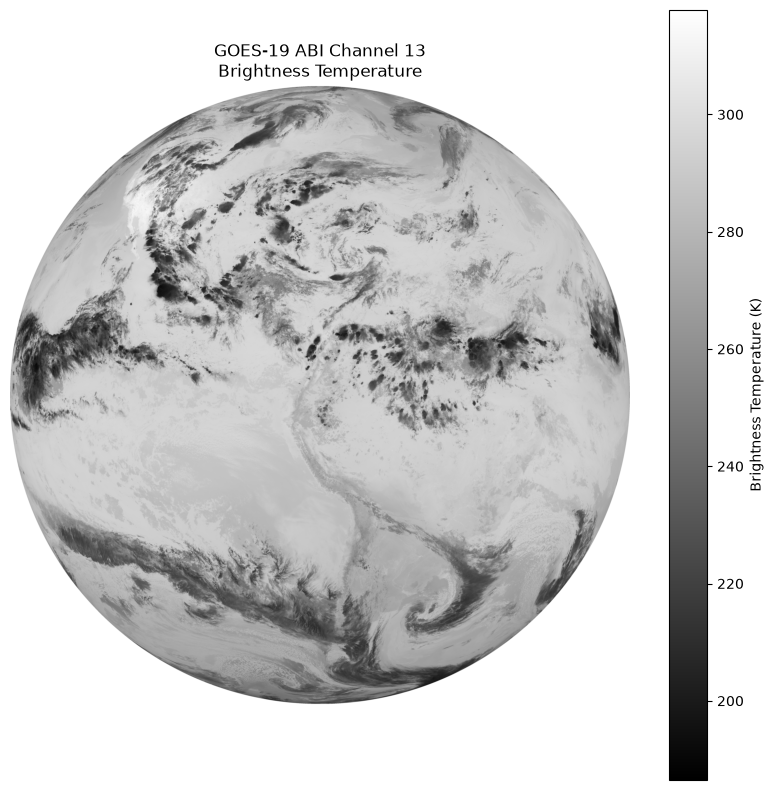

In [44]:
# ============================================================
# Display Brightness Temperature
# ============================================================

plt.figure(figsize=(10, 10))

plt.imshow(
    bt_masked,
    cmap="gray"
)

plt.colorbar(
    label="Brightness Temperature (K)"
)

plt.title(
    "GOES-19 ABI Channel 13\n"
    "Brightness Temperature"
)

plt.axis("off")
plt.show()

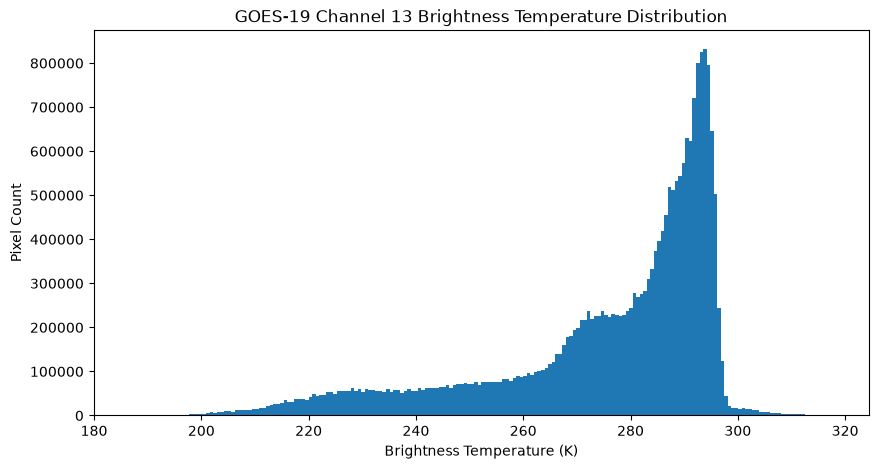

In [45]:
# ============================================================
# Brightness Temperature Histogram
# ============================================================

valid_bt = bt_masked[np.isfinite(bt_masked)]

plt.figure(figsize=(10, 5))

plt.hist(
    valid_bt,
    bins=200
)

plt.xlabel("Brightness Temperature (K)")
plt.ylabel("Pixel Count")
plt.title("GOES-19 Channel 13 Brightness Temperature Distribution")

plt.show()

In [46]:
# ============================================================
# STEP 6
# Estimate GOES-19 BT distribution from TRAINING frames only
# ============================================================

import numpy as np
import xarray as xr
from tqdm.notebook import tqdm

# Use a subset first to avoid loading all 1018 frames into RAM
NUM_SAMPLE_FRAMES = min(50, len(train_df))

sample_indices = np.linspace(
    0,
    len(train_df) - 1,
    NUM_SAMPLE_FRAMES,
    dtype=int
)

all_bt_samples = []

for idx in tqdm(sample_indices, desc="Sampling training frames"):

    filepath = train_df.iloc[idx]["path"]

    with xr.open_dataset(filepath) as ds:

        rad = ds["Rad"].values.astype(np.float32)
        dqf = ds["DQF"].values

        fk1 = float(ds["planck_fk1"].values)
        fk2 = float(ds["planck_fk2"].values)
        bc1 = float(ds["planck_bc1"].values)
        bc2 = float(ds["planck_bc2"].values)

        # Valid radiance
        valid = (
            np.isfinite(rad) &
            (rad > 0) &
            (dqf == 0)
        )

        bt = np.full(
            rad.shape,
            np.nan,
            dtype=np.float32
        )

        bt[valid] = (
            fk2 /
            np.log(
                (fk1 / rad[valid]) + 1.0
            )
        )

        bt[valid] = (
            bt[valid] - bc1
        ) / bc2

        # Randomly sample pixels from valid BT
        valid_bt = bt[np.isfinite(bt)]

        if len(valid_bt) > 0:

            # Maximum 100,000 pixels per frame
            sample_size = min(100_000, len(valid_bt))

            selected = np.random.choice(
                valid_bt,
                size=sample_size,
                replace=False
            )

            all_bt_samples.append(selected)

# Combine sampled pixels
all_bt_samples = np.concatenate(all_bt_samples)

print("Total sampled pixels:", len(all_bt_samples))

print("\nTraining BT distribution")
print("=" * 50)

for p in [0, 0.1, 1, 5, 25, 50, 75, 95, 99, 99.9, 100]:

    print(
        f"{p:5.1f} percentile : "
        f"{np.percentile(all_bt_samples, p):.3f} K"
    )

Sampling training frames:   0%|          | 0/50 [00:00<?, ?it/s]

Total sampled pixels: 5000000

Training BT distribution
  0.0 percentile : 188.121 K
  0.1 percentile : 200.487 K
  1.0 percentile : 215.577 K
  5.0 percentile : 233.094 K
 25.0 percentile : 269.482 K
 50.0 percentile : 284.413 K
 75.0 percentile : 291.612 K
 95.0 percentile : 295.813 K
 99.0 percentile : 300.799 K
 99.9 percentile : 312.949 K
100.0 percentile : 327.405 K


In [47]:
# ============================================================
# STEP 7
# Test fixed physical normalization: 200–320 K
# ============================================================

BT_MIN = 200.0
BT_MAX = 320.0

bt_normalized = (
    bt_masked - BT_MIN
) / (
    BT_MAX - BT_MIN
)

# Clip valid temperature values to [0, 1]
bt_normalized = np.clip(
    bt_normalized,
    0.0,
    1.0
).astype(np.float32)

print("Normalized BT statistics")
print("=" * 50)

valid_norm = bt_normalized[np.isfinite(bt_normalized)]

print("Minimum :", np.min(valid_norm))
print("Maximum :", np.max(valid_norm))
print("Mean    :", np.mean(valid_norm))
print("Std     :", np.std(valid_norm))

Normalized BT statistics
Minimum : 0.0
Maximum : 0.9817861
Mean    : 0.6312188
Std     : 0.17759138


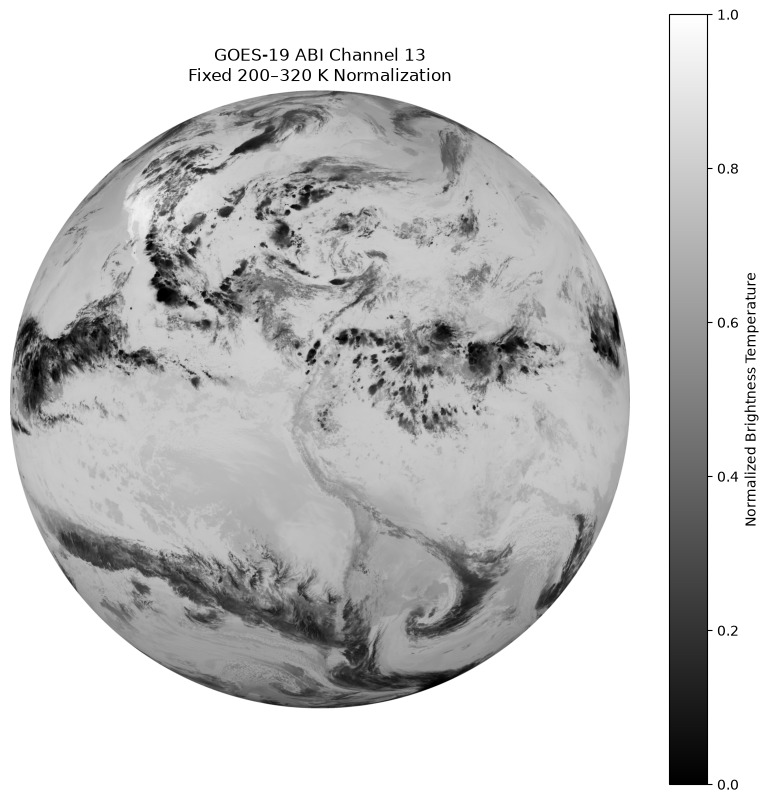

In [48]:
# ============================================================
# Display normalized BT
# ============================================================

plt.figure(figsize=(10, 10))

plt.imshow(
    bt_normalized,
    cmap="gray",
    vmin=0,
    vmax=1
)

plt.colorbar(
    label="Normalized Brightness Temperature"
)

plt.title(
    "GOES-19 ABI Channel 13\n"
    "Fixed 200–320 K Normalization"
)

plt.axis("off")
plt.show()

In [49]:
# ============================================================
# Check clipping percentage
# ============================================================

valid_original = bt_masked[np.isfinite(bt_masked)]

below_min = np.sum(valid_original < BT_MIN)
above_max = np.sum(valid_original > BT_MAX)
total_valid = len(valid_original)

print(
    f"Below {BT_MIN} K : "
    f"{below_min:,} pixels "
    f"({100 * below_min / total_valid:.4f}%)"
)

print(
    f"Above {BT_MAX} K : "
    f"{above_max:,} pixels "
    f"({100 * above_max / total_valid:.4f}%)"
)

print(
    f"Within range    : "
    f"{100 * (1 - (below_min + above_max) / total_valid):.4f}%"
)

Below 200.0 K : 17,538 pixels (0.0761%)
Above 320.0 K : 0 pixels (0.0000%)
Within range    : 99.9239%


In [50]:
# ============================================================
# STEP 8
# Inspect GOES geostationary projection
# ============================================================

projection = sample_ds["goes_imager_projection"]

print("GOES Projection Parameters")
print("=" * 50)

projection_params = {
    "perspective_point_height": float(
        projection.perspective_point_height
    ),
    "semi_major_axis": float(
        projection.semi_major_axis
    ),
    "semi_minor_axis": float(
        projection.semi_minor_axis
    ),
    "latitude_of_projection_origin": float(
        projection.latitude_of_projection_origin
    ),
    "longitude_of_projection_origin": float(
        projection.longitude_of_projection_origin
    ),
    "sweep_angle_axis":
        projection.sweep_angle_axis,
}

for key, value in projection_params.items():
    print(f"{key:35s}: {value}")

GOES Projection Parameters
perspective_point_height           : 35786023.0
semi_major_axis                    : 6378137.0
semi_minor_axis                    : 6356752.31414
latitude_of_projection_origin      : 0.0
longitude_of_projection_origin     : -75.0
sweep_angle_axis                   : x


In [51]:
# ============================================================
# Inspect x/y coordinate ranges
# ============================================================

x = sample_ds["x"].values
y = sample_ds["y"].values

print("X coordinate")
print("Minimum :", x.min())
print("Maximum :", x.max())
print("Shape   :", x.shape)

print("\nY coordinate")
print("Minimum :", y.min())
print("Maximum :", y.max())
print("Shape   :", y.shape)

X coordinate
Minimum : -0.151844
Maximum : 0.151844
Shape   : (5424,)

Y coordinate
Minimum : -0.151844
Maximum : 0.151844
Shape   : (5424,)


In [52]:
# ============================================================
# Create Earth-Disk Mask using GOES Geostationary Projection
# ============================================================

# Projection parameters
H = projection_params["perspective_point_height"]
r_eq = projection_params["semi_major_axis"]
r_pol = projection_params["semi_minor_axis"]

# IMPORTANT:
# CF geostationary perspective_point_height is height above
# the Earth's equatorial radius.
# Therefore satellite distance from Earth's center:
H_sat = H + r_eq

print("GOES Earth Geometry")
print("=" * 50)
print(f"Perspective point height : {H:,.2f} m")
print(f"Equatorial radius        : {r_eq:,.2f} m")
print(f"Polar radius             : {r_pol:,.2f} m")
print(f"Satellite distance       : {H_sat:,.2f} m")

GOES Earth Geometry
Perspective point height : 35,786,023.00 m
Equatorial radius        : 6,378,137.00 m
Polar radius             : 6,356,752.31 m
Satellite distance       : 42,164,160.00 m


In [53]:
# ============================================================
# Calculate Earth-Disk Visibility Mask
# ============================================================

# Convert coordinates to float32 to reduce memory usage
x_rad = x.astype(np.float32)
y_rad = y.astype(np.float32)

# Broadcasting:
# x -> shape (1, 5424)
# y -> shape (5424, 1)

xx = x_rad[None, :]
yy = y_rad[:, None]

# Trigonometric terms
sin_x = np.sin(xx)
cos_x = np.cos(xx)

sin_y = np.sin(yy)
cos_y = np.cos(yy)

# Ellipsoidal geostationary projection equation
A = (
    sin_x**2
    + cos_x**2
    * (
        cos_y**2
        + (r_eq**2 / r_pol**2) * sin_y**2
    )
)

B = -2.0 * H_sat * cos_x * cos_y

C = H_sat**2 - r_eq**2

# Discriminant of the satellite-ray / Earth-ellipsoid intersection
discriminant = B**2 - 4.0 * A * C

# Earth-visible region
earth_mask = discriminant >= 0

print("Earth mask created successfully.")
print("Mask shape :", earth_mask.shape)
print("Earth pixels:", np.sum(earth_mask))
print("Total pixels:", earth_mask.size)
print(
    "Earth coverage: "
    f"{100.0 * np.mean(earth_mask):.2f}%"
)

Earth mask created successfully.
Mask shape : (5424, 5424)
Earth pixels: 23046394
Total pixels: 29419776
Earth coverage: 78.34%


In [54]:
# ============================================================
# Final Valid-Pixel Mask
# ============================================================

valid_bt = np.isfinite(brightness_temperature)

good_quality = (dqf == 0)

final_valid_mask = (
    earth_mask
    & good_quality
    & valid_bt
)

print("Final Valid-Pixel Statistics")
print("=" * 50)

total_pixels = final_valid_mask.size
valid_pixels = np.sum(final_valid_mask)

print(f"Total pixels       : {total_pixels:,}")
print(f"Valid pixels       : {valid_pixels:,}")
print(
    f"Valid percentage   : "
    f"{100.0 * valid_pixels / total_pixels:.2f}%"
)

Final Valid-Pixel Statistics
Total pixels       : 29,419,776
Valid pixels       : 23,046,028
Valid percentage   : 78.34%


In [57]:
# ============================================================
# Brightness Temperature Statistics
# Only Earth + DQF-good pixels
# ============================================================

valid_bt_values = brightness_temperature[final_valid_mask]

print("Valid Brightness Temperature")
print("=" * 50)

print(f"Number of pixels : {len(valid_bt_values):,}")
print(f"Minimum          : {np.min(valid_bt_values):.3f} K")
print(f"Maximum          : {np.max(valid_bt_values):.3f} K")
print(f"Mean             : {np.mean(valid_bt_values):.3f} K")
print(f"Median           : {np.median(valid_bt_values):.3f} K")
print(f"Std              : {np.std(valid_bt_values):.3f} K")

Valid Brightness Temperature
Number of pixels : 23,046,028
Minimum          : 186.487 K
Maximum          : 317.814 K
Mean             : 275.744 K
Median           : 283.924 K
Std              : 21.318 K
